In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [26]:
def plot_probability_space(
    blue_dots=20,
    orange_dots=20,
    title="",
    equations=None,
    margin=0.05,
    seed=None,
    equation_offset=0.08,  # distance between top frame and first equation
):
    """
    Draws blue and orange points inside a unit box with margin.
    Equations appear below the title, above the box.
    """
    if not (0 < margin < 0.5):
        raise ValueError("`margin` must be in (0, 0.5).")

    rng = np.random.default_rng(seed)

    def coords(n):
        return rng.uniform(low=margin, high=1.0 - margin, size=(n, 2))

    b = coords(blue_dots)
    o = coords(orange_dots)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(b[:, 0], b[:, 1], s=60, color="blue", alpha=0.9, edgecolors="none")
    ax.scatter(o[:, 0], o[:, 1], s=60, color="orange", alpha=0.9, edgecolors="none")

    # Formatting
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=14, pad=40)
    ax.set_frame_on(True)

    # Adjust subplot top margin so equations have room
    fig.subplots_adjust(top=1 - (margin / 2))

    # Add equations above the box (below the title)
    if equations:
        y = 1 + equation_offset  # start below title
        step = 0.08
        for eq in equations:
            ax.text(
                0.5,
                y,
                eq,
                transform=ax.transAxes,
                ha="center",
                va="top",
                fontsize=13,
            )
            y -= step

    plt.show()
    return fig, ax

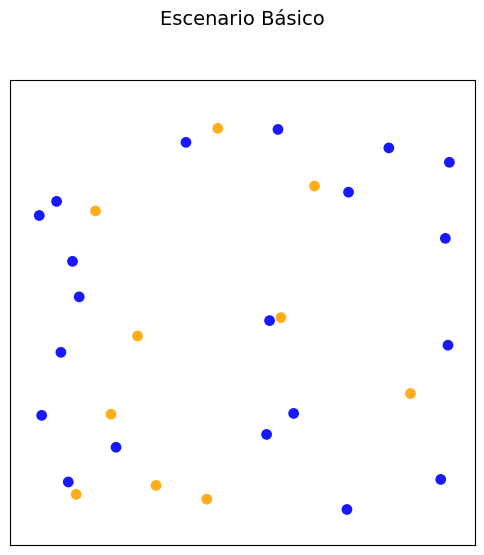

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Escenario Básico'}>)

In [27]:
# Escenario Básico
blue_dots = 20
orange_dots = 10
plot_probability_space(blue_dots,orange_dots, title="Escenario Básico")

In [69]:
# Valores Iniciales
blue_dots = 5
orange_dots = 1

## Probabilidad

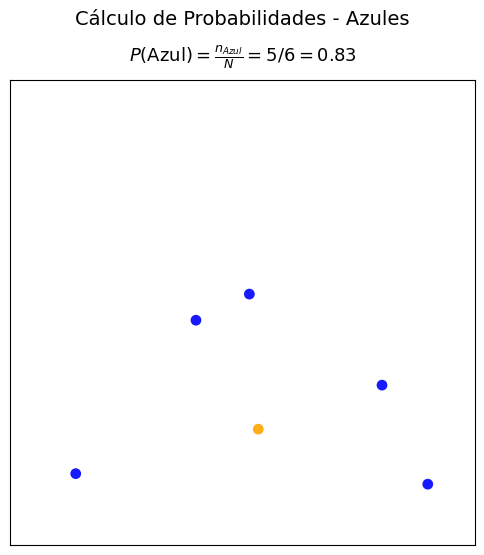

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Cálculo de Probabilidades - Azules'}>)

In [70]:
# Probabilidad de Azules

prob_blue = blue_dots / (blue_dots + orange_dots)

plot_probability_space(
    blue_dots,
    orange_dots,
    title="Cálculo de Probabilidades - Azules",
    equations=[
        rf"$P(\text{{Azul}})=\frac{{n_{{Azul}}}}{{N}}={blue_dots}/{blue_dots + orange_dots}={round(blue_dots / (blue_dots + orange_dots), 2)}$"
    ]
)

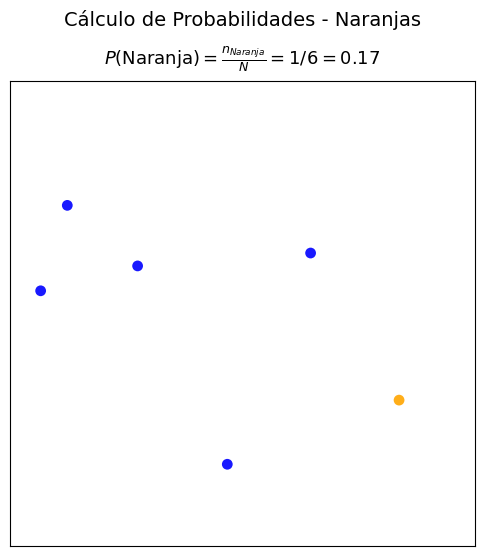

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Cálculo de Probabilidades - Naranjas'}>)

In [71]:
# Probabilidad de Naranjas
prob_orange = orange_dots / (blue_dots + orange_dots)
plot_probability_space(
    blue_dots,
    orange_dots,
    title="Cálculo de Probabilidades - Naranjas",
    equations=[
        rf"$P(\text{{Naranja}})=\frac{{n_{{Naranja}}}}{{N}}={orange_dots}/{blue_dots + orange_dots}={round(orange_dots / (blue_dots + orange_dots), 2)}$"
    ]
)

## Sorpresa

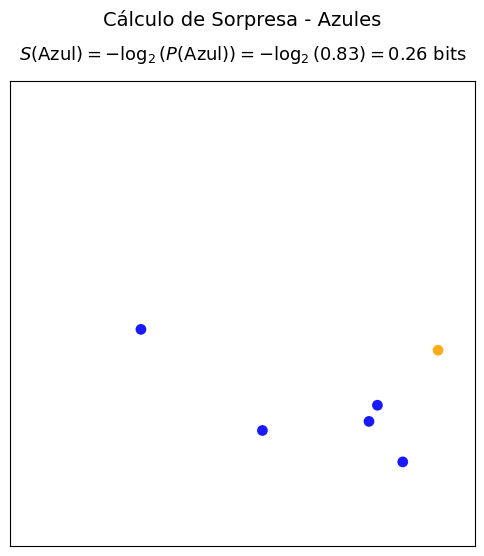

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Cálculo de Sorpresa - Azules'}>)

In [72]:
# Probabilidad de Azules
prob_blue = blue_dots / (blue_dots + orange_dots)

# Sorpresa (en bits)
surprise_blue = -np.log2(prob_blue)

plot_probability_space(
    blue_dots,
    orange_dots,
    title="Cálculo de Sorpresa - Azules",
    equations=[
        rf"$S(\text{{Azul}})=-\log_2(P(\text{{Azul}}))=-\log_2({round(prob_blue, 2)})={round(surprise_blue, 2)} \text{{ bits}}$"
    ]
)

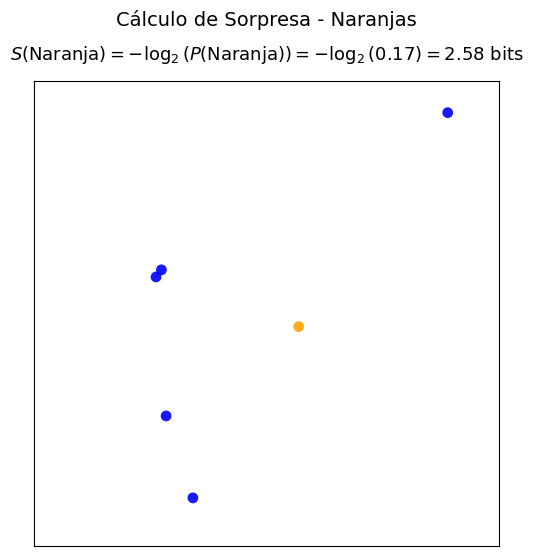

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Cálculo de Sorpresa - Naranjas'}>)

In [73]:
# Probabilidad de Naranjas
prob_orange = orange_dots / (blue_dots + orange_dots)

# Sorpresa (en bits)
surprise_orange = -np.log2(prob_orange)

plot_probability_space(
    blue_dots,
    orange_dots,
    title="Cálculo de Sorpresa - Naranjas",
    equations=[
        rf"$S(\text{{Naranja}})=-\log_2(P(\text{{Naranja}}))=-\log_2({round(prob_orange, 2)})={round(surprise_orange, 2)} \text{{ bits}}$"
    ]
)

## Entropía

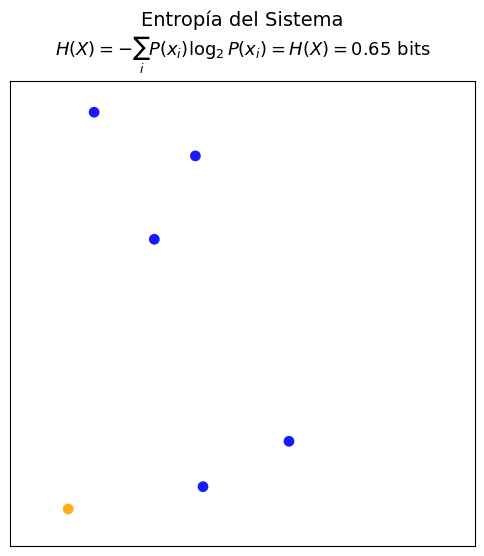

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': 'Entropía del Sistema'}>)

In [74]:
# Probabilidades
p_blue = blue_dots / (blue_dots + orange_dots)
p_orange = orange_dots / (blue_dots + orange_dots)

# Entropía (en bits)
H = -(p_blue * np.log2(p_blue) + p_orange * np.log2(p_orange))

plot_probability_space(
    blue_dots,
    orange_dots,
    title="Entropía del Sistema",
    equations=[

        rf"$H(X)=-\sum_i P(x_i)\log_2 P(x_i) = H(X)={round(H,2)}\ \text{{bits}}$"
    ],
    equation_offset=0.1,
)